# First Visualization: Median Participant Enrollment by Condition Group

This visualization compares the median number of participants enrolled in female-specific and male-specific clinical trials. Only trials with actual enrollment data are included.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

#Loading the cleaned clinical trial data
df = pd.read_csv("clinical_trials_clean.csv")
df.head()

,nct_id,title,condition_group,condition,female_specific,study_type,phase,phase_group,overall_status,why_stopped,...,enrollment_type,log_enrollment,enrollment_outlier,num_locations,start_date,start_year,completion_date,completion_type,duration_months,duration_actual_months
0,NCT04107129,Predicting Endometrial Receptivity for Optimal...,Female-specific,Endometriosis,1,OBSERVATIONAL,NaN,Observational,COMPLETED,NaN,...,ACTUAL,4.343805,0,1,2020-07-01,2020,2024-07-30,ACTUAL,48.9,48.9
1,NCT06414083,Histologic Comparison of Ablative Techniques f...,Female-specific,Endometriosis,1,INTERVENTIONAL,NO_PHASE,No phase,RECRUITING,NaN,...,ESTIMATED,4.955827,0,1,2024-05-09,2024,2025-06-09,ESTIMATED,13.0,NaN
2,NCT05560646,A Study to Investigate Efficacy and Safety of ...,Female-specific,Endometriosis,1,INTERVENTIONAL,PHASE2,Phase 2,COMPLETED,NaN,...,ACTUAL,5.872118,0,86,2022-10-25,2022,2025-05-28,ACTUAL,31.1,31.1
3,NCT01056042,Efficacy of Injectable Contraceptive and Oral ...,Female-specific,Endometriosis,1,INTERVENTIONAL,PHASE4,Phase 4,COMPLETED,NaN,...,ESTIMATED,4.727388,0,1,2007-06-01,2007,2011-10-01,ACTUAL,52.0,52.0
4,NCT02427386,Homeopathic Treatment of Chronic Pelvic Pain i...,Female-specific,Endometriosis,1,INTERVENTIONAL,PHASE4,Phase 4,COMPLETED,NaN,...,ACTUAL,3.931826,0,0,2014-05-01,2014,2016-12-01,ACTUAL,31.0,31.0


In [2]:
#Retrieving column names in data
df.columns.tolist()

['nct_id',
 'title',
 'condition_group',
 'condition',
 'female_specific',
 'study_type',
 'phase',
 'phase_group',
 'overall_status',
 'why_stopped',
 'ended_early',
 'sponsor_class',
 'industry_sponsor',
 'sex_eligibility',
 'sex_mismatch',
 'enrollment',
 'enrollment_type',
 'log_enrollment',
 'enrollment_outlier',
 'num_locations',
 'start_date',
 'start_year',
 'completion_date',
 'completion_type',
 'duration_months',
 'duration_actual_months']

In [3]:
#Checking the types of enrollment in data
df["enrollment_type"].value_counts(dropna=False)

enrollment_type
ACTUAL       3771
ESTIMATED    2276
NaN           144
Name: count, dtype: int64

In [4]:
#Distinguish the trials with actual enrollments
actual_trials = df[df['enrollment_type'] == "ACTUAL"]

#Comparing the median enrollment between condition groups
median_enrollment = actual_trials.groupby("condition_group")["enrollment"].median()
median_enrollment

condition_group
Female-specific    65.0
Male-specific      80.0
Name: enrollment, dtype: float64

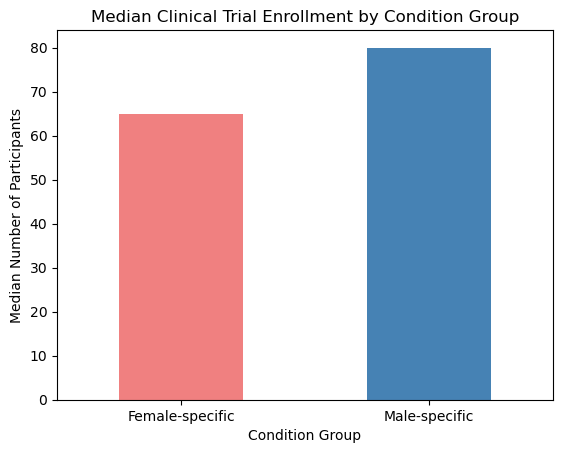

In [5]:
#Bar Chart
median_enrollment.plot(kind="bar", color=["lightcoral", "steelblue"])

plt.title("Median Clinical Trial Enrollment by Condition Group")
plt.xlabel("Condition Group")
plt.ylabel("Median Number of Participants")
plt.xticks(rotation=0)
plt.show()

### Interpretation

Among clinical trials reporting actual enrollment, male-specific trials had a median enrollment of 80 participants, compared to 65 participants for female-specific trials. This is a difference of 15 participants, suggesting that male-specific trials in this dataset tend to have slightly higher enrollment. However, this comparison alone does not explain why the difference exists.

# Second Visualization: Clinical Trial Status by Condition Group

This visualization will compare the percentages of withdrawn, completed, and terminated clinical trials between female-specific and male-specific conditions.

In [6]:
#Checking the different clinical trial statuses
df["overall_status"].value_counts(dropna = False)

overall_status
COMPLETED                  3374
UNKNOWN                    1043
RECRUITING                  659
NOT_YET_RECRUITING          379
TERMINATED                  321
ACTIVE_NOT_RECRUITING       181
WITHDRAWN                   170
ENROLLING_BY_INVITATION      49
SUSPENDED                    15
Name: count, dtype: int64

In [7]:
#Finding the trials that were either completed, terminated, or withdrawn
finished_trials = df[df["overall_status"].isin(
    ["COMPLETED", "TERMINATED", "WITHDRAWN"]
)]

#Counting female/male specific status
status_counts = pd.crosstab(
    finished_trials["condition_group"],
    finished_trials["overall_status"]
)

#Conversion of counts into a percentage value
status_percentages = status_counts.div(
    status_counts.sum(axis = 1), axis = 0
) * 100

status_percentages

overall_status,COMPLETED,TERMINATED,WITHDRAWN
condition_group,,,
Female-specific,87.081162,8.786299,4.132539
Male-specific,87.786260,7.209500,5.004241


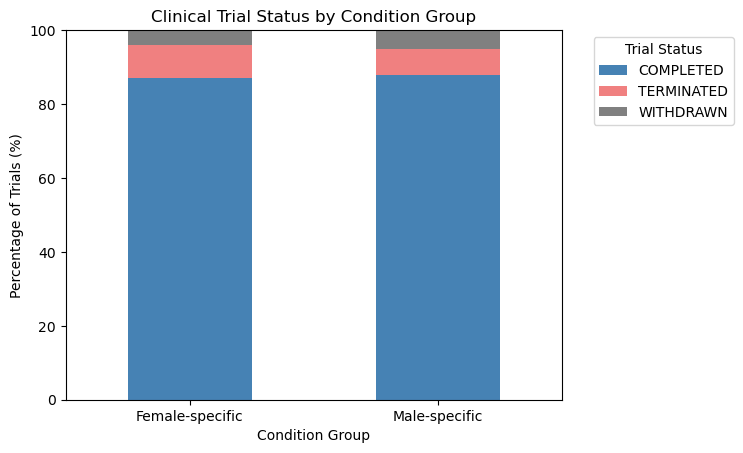

In [8]:
#Stacked Bar Chart
status_percentages.plot(
    kind="bar",
    stacked=True,
    color=["steelblue", "lightcoral", "gray"]
)

plt.title("Clinical Trial Status by Condition Group")
plt.xlabel("Condition Group")
plt.ylabel("Percentage of Trials (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Trial Status", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

## Interpretation

Both condition groups had a similar completion percentage under the completed, terminated, and withdrawn classified trials. Around 87.08% and 87.79% of the female and male specific trials were completed, correspondingly. The male specific trials had a higher withdrawal percentage of 5.00% compared to the female specific trials of 4.13%. The female-specific trials had a higher termination percentage of 8.79% compared to the male-specific trial of 7.21%. In general, these differences were not drastic and relatively similar. Additionally, completion of a trial does not mean the success of a trial. These percentage values only include trials with one of the three selected statuses.

# Ethical Implications

When using clinical trial data to compare female specific and male specific conditions, there are several ethical considerations that are involved. Unequal representation in clinical trial data sets is one of the main concerns. Specific conditions may have more studies done than others, which could ultimately impact the results and potentially create bias in an analysis. On top of this, the total number of participants enrolled in a clinical trial doesn't necessarily represent the amount of attention or funding that was invested into a condition. Other factors that influence enrollment are prevalence of a condition, eligibility requirements, and study design.

Additionally, another concern is the machine learning interpretation level in these differences. A model that is trained on data that consists of inequalities within the research participation could reinforce the same patterns rather than providing an unbiased prediction. It is crucial to realize that classifying conditions as female specific or male specific doesn't fully represent everyone affected by these conditions. This includes transgender and non-binary individuals. Keeping the above information in mind, any conclusions made from this project should be interpreted carefully and should not be used alone to make decisions about research, funding, or healthcare priorities.

# Machine Learning Evaluation Function: Mean Absolute Error (MAE)

This function will find the Mean Absolute Error (MAE) of a machine learning model. MAE measures the average difference between predicted and actual numerical values. For this project, it could be used to evaluate how accurately a regression model predicts clinical trial enrollment. A lower MAE indicates that the model's predictions are closer to the actual enrollment values.

In [9]:
# Function to calculate Mean Absolute Error
def calculate_mae(actual, predicted):
    errors = []
    # Finding the absolute differences
    for i in range(len(actual)):
        error = abs(actual[i] - predicted[i])
        errors.append(error)
    # Finding the average error
    mae = sum(errors) / len(errors)
    
    return mae

In [10]:
#Testing the function with an example value set
actual = [100, 200, 150, 300]
predicted = [110, 180, 160, 290]

print(calculate_mae(actual, predicted))

12.5
